In [1]:
import os
import numpy as np
import pandas as pd
import json 
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Rectangle
import seaborn as sns

from scipy.stats import mannwhitneyu, kruskal
from statsmodels.stats.multitest import fdrcorrection
from statannotations.Annotator import Annotator
import scikit_posthocs as sp
from itertools import combinations
from scipy.stats import pearsonr
from statsmodels.formula.api import ols
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

import itertools
from scipy.stats import chi2_contingency, fisher_exact

from morph_utils.query import get_id_by_name
from morph_utils.templates import load_layer_template
from neuron_morphology.swc_io import morphology_from_swc

import warnings

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, format_box_plot


sns.set_context("notebook")
plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator

/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Box plots comparing macaque and human electrophysiology features by Great Ape Consensus Taxonomy cluster 
And then comaring all species (adding mouse) at subclass level

In [2]:
species_type = 'primate' #species #primate 


In [3]:
depth_type = 'layer' # depth_in_layer_norm used to define superficial/deep L2/3 IT groups
# depth_type = 'pia' # depth_from_pia_norm used to define superficial/deep L2/3 IT groups

include_pseq_tea = False #whether to include Patch-seq TEa data

##################################
if depth_type == 'pia':
    depth_column = 'depth_from_pia_norm'
    #thresholds for defining superficial and deep from depth_from_pia_norm 
    lower_thresh = 0.15
    middle_thresh = 0.25
    upper_thresh = 0.45
else:
    depth_column = 'depth_in_layer_norm_new'
    #thresholds for defining superficial and deep from depth_in_layer_norm 
    lower_thresh = 0.2
    middle_thresh = 0.5
    upper_thresh = 1

In [4]:
#human
h_subclass_col = 'subclass_label_Hierarchical' 
h_cluster_col = 'cluster_label_Hierarchical' 

#macaque
p_subclass_col =  'subclass_Corr_label_RSC_204_389'
p_cluster_col =   'cluster_Corr_label_RSC_204_389'

#mouse
m_subclass_col =  'subclass'
m_cluster_col =  't_type'

#rename to
subclass_col =  'subclass'
cluster_col =   'cluster'

In [5]:
# Save root 
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

# HUMAN TemL
human_metadata_file =     DATA_ROOT / 'human' / 'metadata'   / '20260807' / 'human_metadata.csv'
human_feature_file =      DATA_ROOT / 'human' / 'electrophysiology' / 'features_cross_species' / '20260908' / 'ephys_features.csv'

# MACAQUE TemL
macaque_metadata_file =         DATA_ROOT / 'macaque' / 'metadata'   / '20260722' / 'macaque_metadata.csv'
macaque_feature_file =          DATA_ROOT / 'macaque' / 'electrophysiology' / '20260908' / 'ephys_features.csv'

# MOUSE TEa
mouse_metadata_file =     DATA_ROOT / 'mouse' / 'metadata'   / '20260826' / 'mouse_metadata.csv'
mouse_feature_file =      DATA_ROOT / 'mouse' / 'electrophysiology' / '20260908' / 'ephys_features.csv'

# depth alignment
l23_grouping_file =         OUT_DIR / f'l23_comparison_{depth_type}.csv'

#colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'

#subclass order
subclass_order_file =         DATA_ROOT / 'formatting_dicts' / 'subclass_order.txt'

In [6]:
# Load feature files only (taxonomy already included in cross_subclass column)
# HUMAN TemL
human_raw_feature_wide = pd.read_csv(human_feature_file)

# MACAQUE TemL
macaque_raw_feature_wide = pd.read_csv(macaque_feature_file)

# MOUSE TEa
mouse_raw_feature_wide = pd.read_csv(mouse_feature_file)

#depth matching groups for L2/3 IT subclass
l23_grouping_data = pd.read_csv(l23_grouping_file)

#colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))
species_colors['mouse TEa'] = '#c9416a'
species_colors['mouse VIS'] = species_colors['mouse']

#get plotting color dict
color_dict = get_seaad_colors()
color_dict['L2/3 IT_superficial'] = color_dict['L2/3 IT']
color_dict['L2/3 IT_deep'] = color_dict['L2/3 IT']

In [7]:
cluster_var_name = subclass_col

# Use taxonomy directly from feature files (cross_subclass column)
# This preserves all cells with ephys features, not just those with morphology metadata
human_data = human_raw_feature_wide.copy()
human_data['subclass'] = human_data['cross_subclass']
human_data['cluster'] = 'Unknown'
human_data['species'] = 'human'

macaque_data = macaque_raw_feature_wide.copy()
macaque_data['subclass'] = macaque_data['cross_subclass']
macaque_data['cluster'] = 'Unknown'
macaque_data['species'] = 'macaque'

mouse_data = mouse_raw_feature_wide.copy()
mouse_data['subclass'] = mouse_data['cross_subclass']
mouse_data['cluster'] = 'Unknown'
mouse_data['species'] = 'mouse'

#select region/species data to analyze
if species_type == 'species':
    data = pd.concat([human_data, macaque_data, mouse_data])
elif species_type == 'primate':
    data = pd.concat([human_data, macaque_data])
else: raise ValueError(f'Unknown species_type: {species_type}')

# #drop columns with too many NaN values
# cols_to_drop = data.columns[data.isna().sum() >= 50]
# data = data.drop(columns=cols_to_drop)

In [8]:
if species_type == 'species':
    #restrict data to L5 for including this mouse TEa dataset (it doesn't have enough L2/3 cells to compare)
    data = data[data.subclass.isin(['L5 IT', 'L5 ET'])]
elif species_type == 'primate':
    data = data[data.subclass.isin(['L2/3 IT', 'L5 IT',  'L5/6 NP', 'L5 ET'])]
else: raise ValueError(f'Unknown species_type: {species_type}')

In [9]:
data.subclass.value_counts()

L5 IT    266
L5 ET     60
Name: subclass, dtype: int64

In [10]:
len(data)

326

In [11]:
# L2/3 IT subclass depth mathing 
l23_grouping_col = 'depth_group_two' 

#append the grouping to L2/3 IT subclass name (i.e. '_superficial', '_deep')
id_to_group = l23_grouping_data.set_index('specimen_id')[l23_grouping_col]
mask = data.specimen_id.isin(id_to_group.index)
data.loc[mask, 'subclass'] = (
    data.loc[mask, 'subclass'] + '_' + data.loc[mask, 'specimen_id'].map(id_to_group)
)

data = data[data.subclass != 'L2/3 IT'] # remove the L2/3 IT cells that did not have a depth match, these are < 0.2 normalized depth, and so are likely Layer 2 cells (macaque doesn't have any)

In [12]:
len(data)

326

In [13]:
#feature differentiation 
meta_cols = ['specimen_id', 'subclass', 'cluster', 'species']
feature_cols = [c for c in data.columns if c not in meta_cols]

In [14]:
# Filter to only include ephys features starting with 'combined'
combined_features = [f for f in feature_cols if f.startswith('combined')]
print(f"Total features before filtering: {len(feature_cols)}")
print(f"Features starting with 'combined': {len(combined_features)}")
print(f"Combined features: {combined_features}")

# Load the ephys feature rename CSV
ephys_rename_file = DATA_ROOT / 'formatting_dicts' / 'ephys_feature_rename.csv'
ephys_rename_df = pd.read_csv(ephys_rename_file)
feature_rename_dict = dict(zip(ephys_rename_df['old_feature_name'], ephys_rename_df['new_feature_name']))

# Check for any combined features not in the rename CSV
missing_features = [f for f in combined_features if f not in feature_rename_dict]
if missing_features:
    print(f"\n⚠️  WARNING: The following ephys features are NOT in the rename CSV:")
    for f in missing_features:
        print(f"  - {f}")
else:
    print(f"\n✓ All {len(combined_features)} combined features found in rename CSV")

# Apply the rename mapping to data columns
data = data.rename(columns=feature_rename_dict)

# Update feature_cols to only include the renamed combined features
renamed_combined_features = [feature_rename_dict.get(f, f) for f in combined_features]
feature_cols = renamed_combined_features

print(f"\nUpdated feature_cols with {len(feature_cols)} renamed features:")
for f in feature_cols:
    print(f"  - {f}")

Total features before filtering: 22
Features starting with 'combined': 15
Combined features: ['combined_updown_ratio', 'combined_width', 'combined_upstroke', 'combined_downstroke', 'combined_sag', 'combined_baseline', 'combined_input_resistance_SS', 'combined_tau', 'combined_ap_peak', 'combined_trough_v', 'combined_fast_trough_v', 'combined_peak_freq_chirp', 'combined_ap_threshold', 'combined_peak_impedance_chirp', 'combined_ap_height']

✓ All 15 combined features found in rename CSV

Updated feature_cols with 15 renamed features:
  - AP up/down ratio
  - AP width (ms)
  - AP ustroke
  - AP downstroke
  - Sag
  - Resting membrane potential (RMP)
  - Input resistance
  - Tau
  - AP peak
  - Trough voltage
  - Fast trough voltage
  - Chirp peak
  - AP threshold
  - ZAP (peak impedance)
  - AP height


In [15]:
len(feature_cols)

15

In [16]:
#cluster order 
subclass_order = pd.read_csv(subclass_order_file, header=None, names=['cluster'])['cluster'].tolist()
index = subclass_order.index('L2/3 IT')
subclass_order = subclass_order[:index] + ['L2/3 IT_superficial', 'L2/3 IT_intermediate', 'L2/3 IT_deep'] + subclass_order[index+1:]
subclass_order = [c for c in subclass_order if c in data['subclass'].unique()]

In [17]:
data.to_csv(os.path.join(OUT_DIR, f'{species_type}_subclass_data_ephys.csv'), index=False)

Box plots

In [18]:
x_var = 'subclass'
x_var_order = subclass_order
features = feature_cols.copy()

species_order = [x for x in ['human', 'macaque', 'mouse'] if x in data['species'].dropna().unique().tolist()]

mn_pvals = {f: {} for f in features}
mn_test_type = {f: {} for f in features}
mn_posthoc_pvals = {f: {} for f in features}

# STEP 1: Compute all main tests (Mann-Whitney or Kruskal)
for f in features:
    for var in x_var_order:

        groups = {
            species: data.loc[
                (data[x_var] == var) & (data['species'] == species),
                f
            ].dropna().tolist()
            for species in species_order
        }

        non_empty = {k: v for k, v in groups.items() if len(v) > 0}

        if len(non_empty) < 2:
            print(f"Skipping {f} in {var}: fewer than two species have values.")
            mn_pvals[f][var] = np.nan
            mn_test_type[f][var] = 'none'
            continue

        try:
            species_list = list(non_empty.keys())
            vals = list(non_empty.values())

            if len(non_empty) == 2:
                stat, pval = mannwhitneyu(vals[0], vals[1], nan_policy='omit')
                mn_test_type[f][var] = 'mannwhitneyu'
                mn_pvals[f][var] = pval

            else:
                stat, pval = kruskal(*vals, nan_policy='omit')
                mn_test_type[f][var] = 'kruskal'
                mn_pvals[f][var] = pval

        except Exception as e:
            print(f"Couldn't compute stats for {f} in {var}: {e}")
            mn_pvals[f][var] = np.nan
            mn_test_type[f][var] = 'error'


# STEP 2: Apply FDR correction ACROSS ALL TESTS (not within features)
mn_pvals_fdr = {}
mn_pvals_rejected = {}

# Collect ALL p-values from all features and subclasses
all_pvals = []
all_keys = []  # (feature, subclass) tuples

for f in features:
    for var in x_var_order:
        pval = mn_pvals[f].get(var, np.nan)
        if not np.isnan(pval):
            all_pvals.append(pval)
            all_keys.append((f, var))

print(f"Applying FDR correction across {len(all_pvals)} total tests (all features x subclasses)")

# Apply single FDR correction across ALL tests
if len(all_pvals) > 0:
    rejected, pvals_fdr = fdrcorrection(all_pvals, alpha=0.05)
    
    # Map corrected p-values back to feature/subclass structure
    fdr_dict = {key: (fdr_p, rej) for key, fdr_p, rej in zip(all_keys, pvals_fdr, rejected)}
    
    # Populate the dictionaries
    for f in features:
        mn_pvals_fdr[f] = {}
        mn_pvals_rejected[f] = {}
        for var in x_var_order:
            if (f, var) in fdr_dict:
                mn_pvals_fdr[f][var] = fdr_dict[(f, var)][0]
                mn_pvals_rejected[f][var] = fdr_dict[(f, var)][1]
            else:
                mn_pvals_fdr[f][var] = np.nan
                mn_pvals_rejected[f][var] = False
else:
    # No valid p-values
    for f in features:
        mn_pvals_fdr[f] = {k: np.nan for k in mn_pvals[f].keys()}
        mn_pvals_rejected[f] = {k: False for k in mn_pvals[f].keys()}

print(f"Number of tests with FDR p < 0.05: {sum(rejected)}")


# STEP 3: Compute posthoc tests for significant Kruskal results (FDR p < 0.05)
for f in features:
    for var in x_var_order:
        # Initialize empty posthoc results
        mn_posthoc_pvals[f][var] = {}
        
        # Gate on FDR-corrected p-value
        fdr_p = mn_pvals_fdr[f].get(var, np.nan)
        if pd.isna(fdr_p) or fdr_p >= 0.05:
            continue
        
        # Skip if not a Kruskal test (Mann-Whitney doesn't need posthoc)
        if mn_test_type[f][var] != 'kruskal':
            # For Mann-Whitney, store the main test result as posthoc
            groups = {
                species: data.loc[
                    (data[x_var] == var) & (data['species'] == species),
                    f
                ].dropna().tolist()
                for species in species_order
            }
            non_empty = {k: v for k, v in groups.items() if len(v) > 0}
            species_list = list(non_empty.keys())
            if len(species_list) == 2:
                mn_posthoc_pvals[f][var] = {
                    f"{species_list[0]}_vs_{species_list[1]}": mn_pvals_fdr[f][var]
                }
            continue
        
        # Perform posthoc Dunn test for FDR-significant Kruskal results
        try:
            groups = {
                species: data.loc[
                    (data[x_var] == var) & (data['species'] == species),
                    f
                ].dropna().tolist()
                for species in species_order
            }
            non_empty = {k: v for k, v in groups.items() if len(v) > 0}
            species_list = list(non_empty.keys())
            vals = list(non_empty.values())
            
            posthoc = sp.posthoc_dunn(vals, p_adjust='fdr_bh')
            mn_posthoc_pvals[f][var] = {
                f"{species_list[i]}_vs_{species_list[j]}": posthoc.iloc[i, j]
                for i, j in combinations(range(len(species_list)), 2)
            }
        except Exception as e:
            print(f"Couldn't compute posthoc for {f} in {var}: {e}")
            mn_posthoc_pvals[f][var] = {}

Applying FDR correction across 30 total tests (all features x subclasses)
Number of tests with FDR p < 0.05: 9


In [19]:
if species_type == 'species':
    figsize = (3, 5)

elif species_type == 'primate':
    figsize = (5, 5)

else: raise ValueError(f'Unknown species_type: {species_type}')


box_width = 0.7
compartment='ephys'
plot_stats = True

if not data.index.is_unique:
    data = data.reset_index(drop=True)

# Temporarily reduce font size for annotations
original_fontsize = plt.rcParams['font.size']
plt.rcParams['font.size'] = 2  # smaller stars

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:3.128e-05


/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)
/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 ET_human vs. L5 ET_macaque: Custom statistical test, P_val:4.546e-05
L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:1.540e-03


/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:2.089e-02


/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


... (6 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:1.417e-02


/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:1.169e-06


/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)
/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)
/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)
/tmp/ipykernel_3502829/3831155703.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


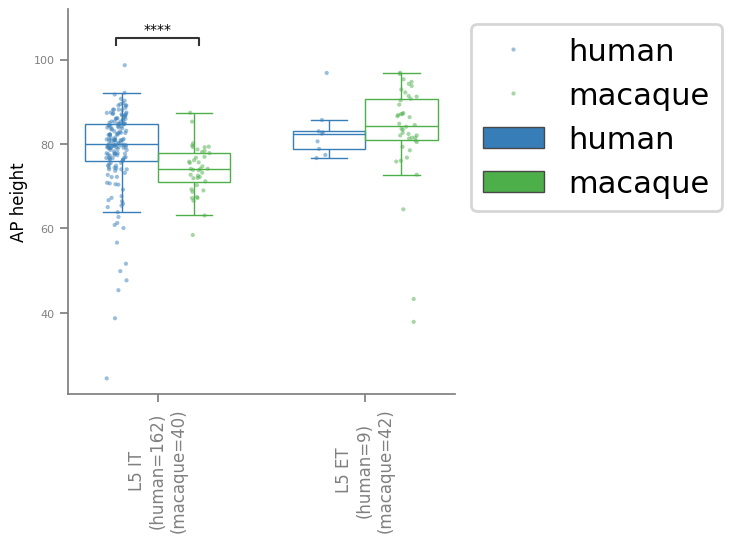

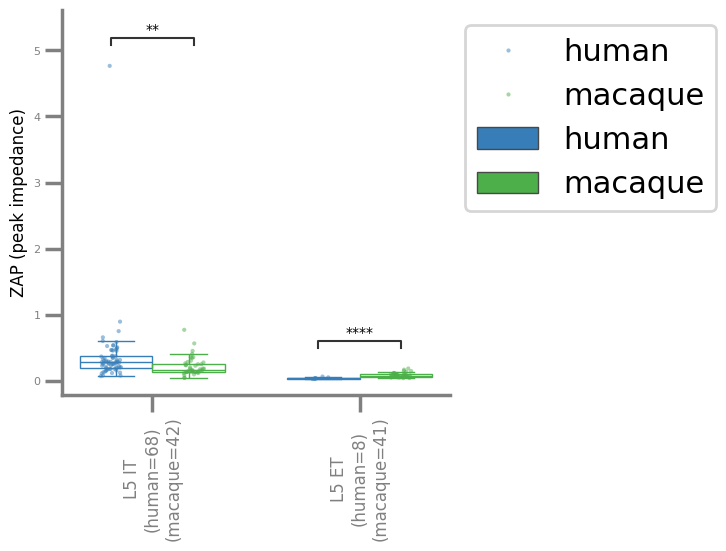

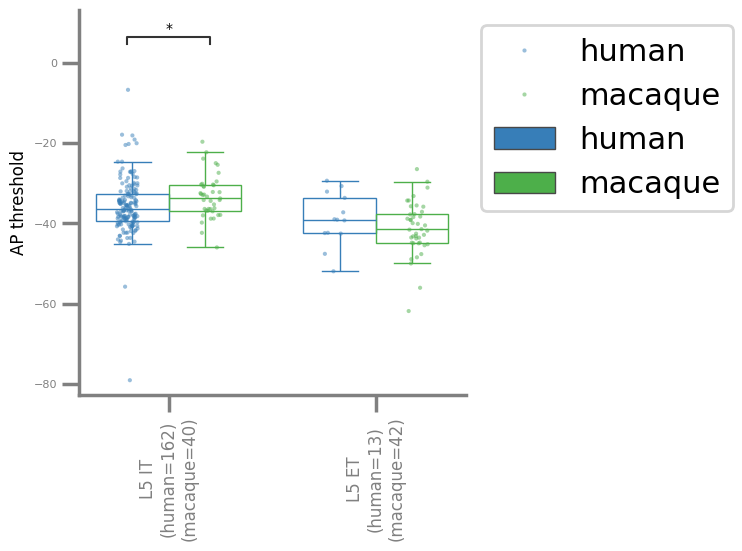

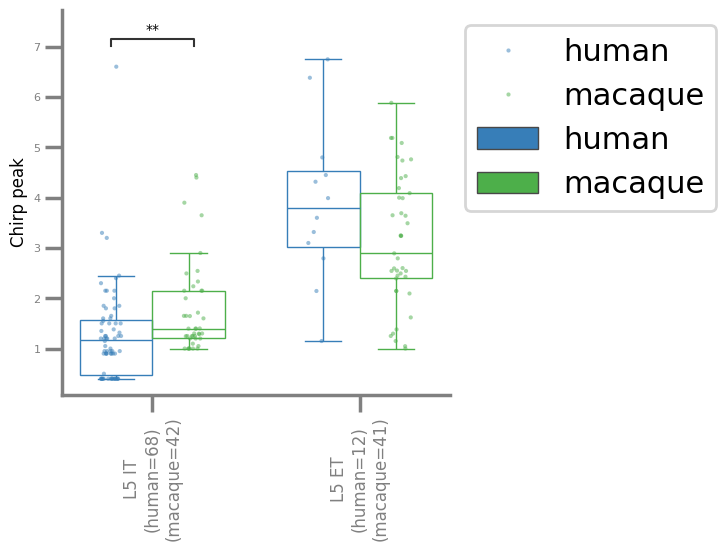

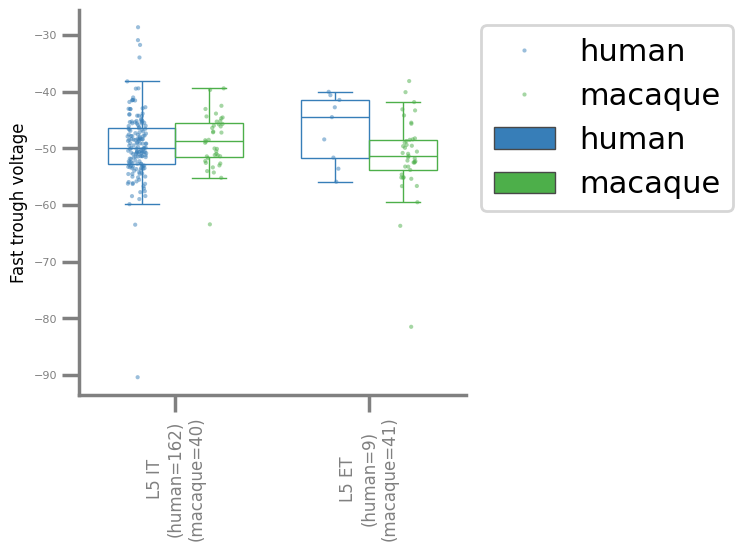

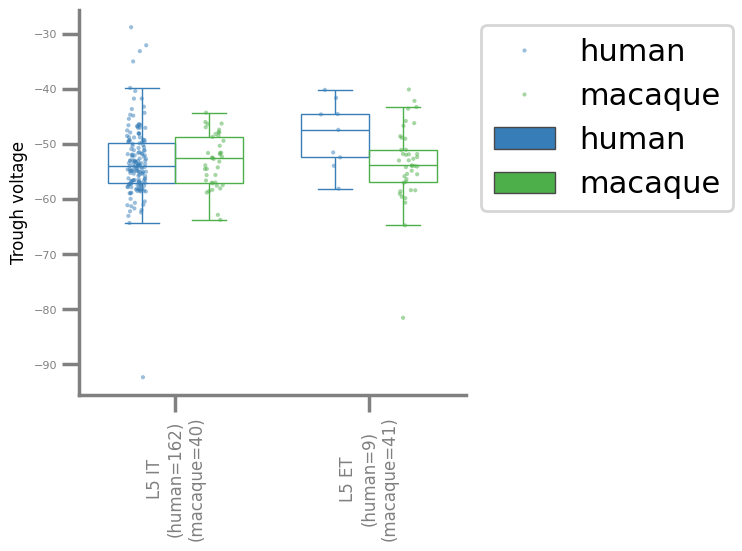

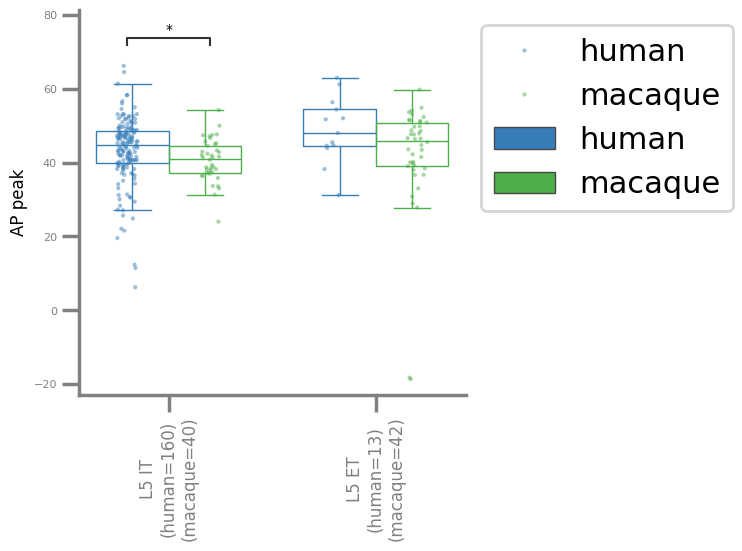

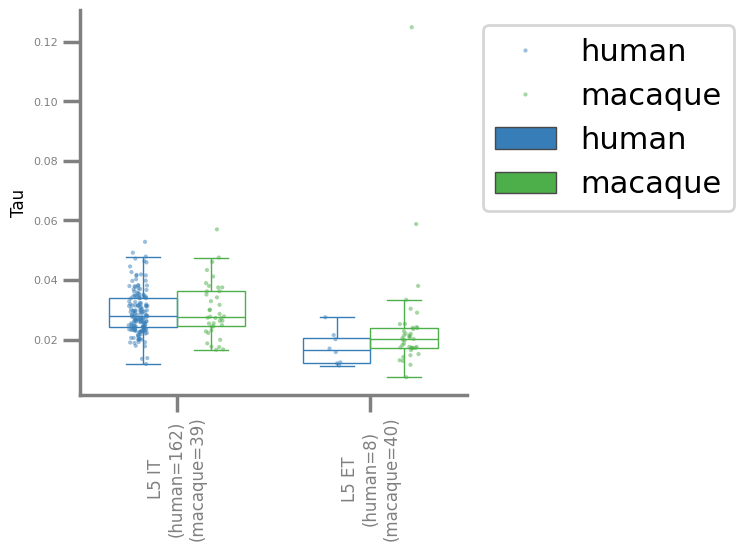

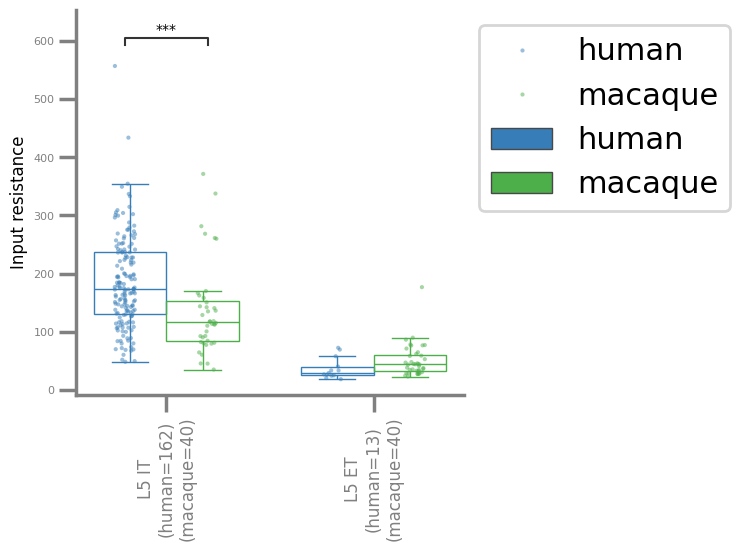

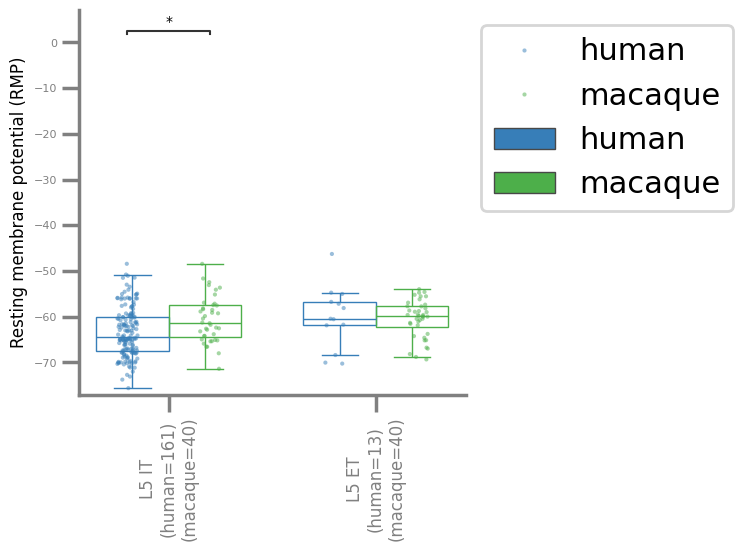

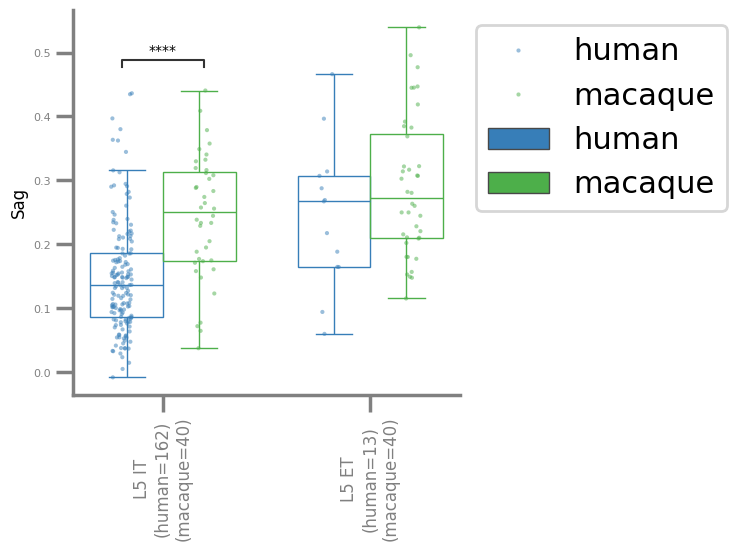

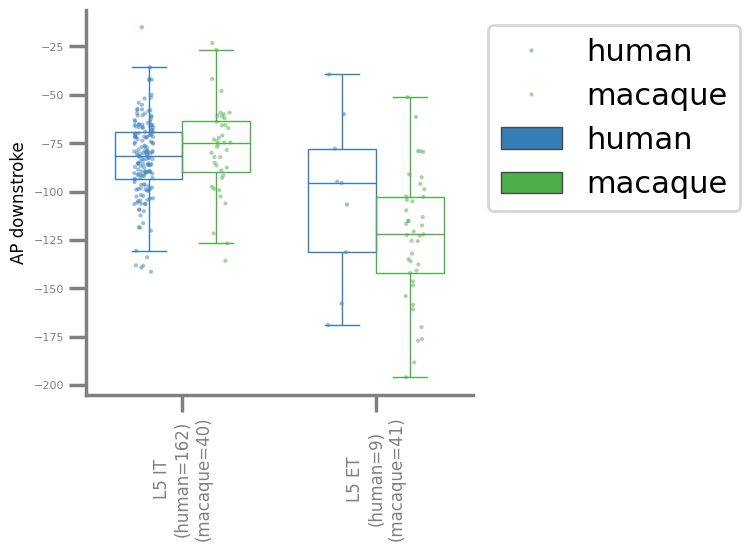

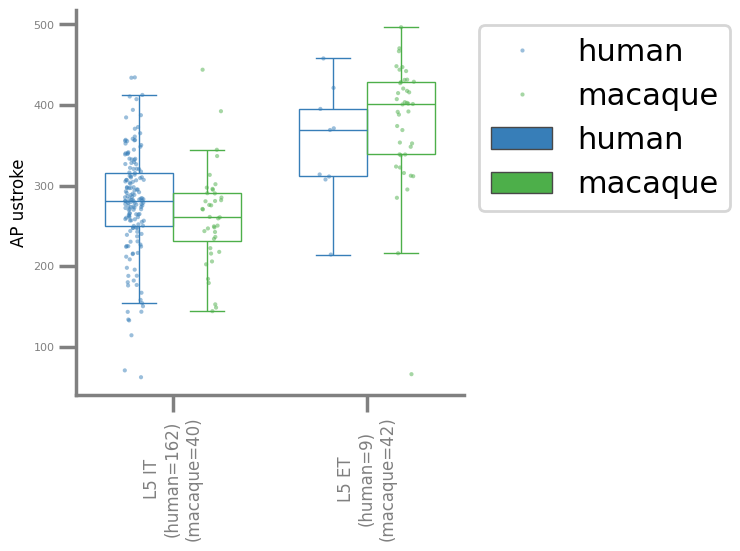

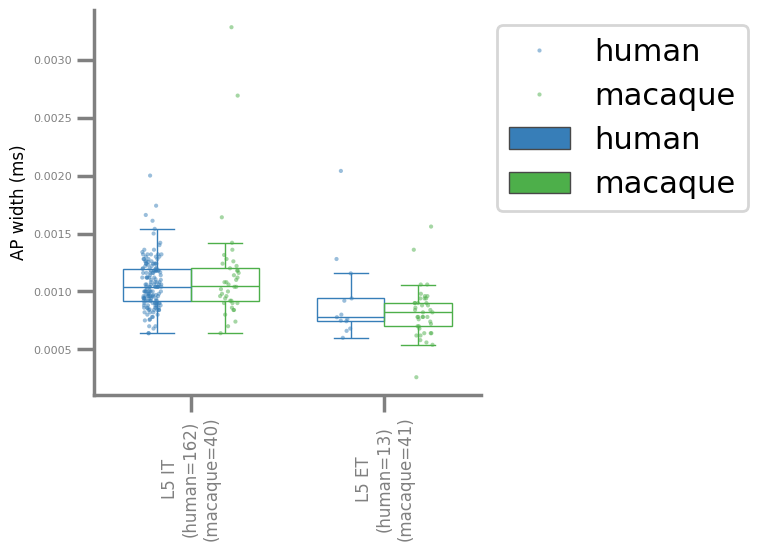

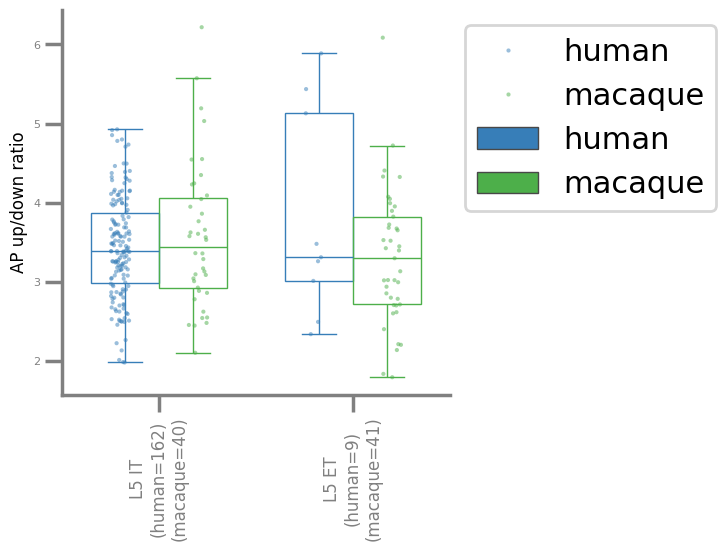

<Figure size 640x480 with 0 Axes>

In [20]:
fig_name = f'{species_type}_subclass_ephys_feature_box_plots.pdf'
if plot_stats: 
    fig_name = fig_name.replace('.pdf', '_statsAnnotated.pdf')
fig_path = os.path.join(OUT_DIR, fig_name)

features = feature_cols.copy()
with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while features != []:
            
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=figsize,sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            
            #grab a feature
            y_var = features.pop()

            #plot
            sns.set_context('poster')
            sns.stripplot(data=data, x=x_var, y=y_var, hue='species', palette=species_colors, order=x_var_order, alpha=0.5, dodge=True, size=3)
            sns.boxplot(data=data, x=x_var, y=y_var, hue='species', palette=species_colors, order=x_var_order, saturation=1, linewidth=1, width=box_width, showfliers = False)
            plt.legend(loc='upper left', bbox_to_anchor=(1, 1))

            # format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set(xlabel=None)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=12)
            ax.tick_params(axis='x', rotation=90, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)

            #add num observations per x_var (only count non-NaN values for the current feature)
            nobs = []
            for t in x_var_order:
                nq = len(data[(data[x_var] == t) & (data.species == 'macaque') & data[y_var].notna()])
                nh = len(data[(data[x_var] == t) & (data.species == 'human') & data[y_var].notna()])
                nm = len(data[(data[x_var] == t) & (data.species == 'mouse') & data[y_var].notna()])
                if species_type == 'primate':
                    nobs.append(f"{t}\n(human={nh})\n(macaque={nq})")
                elif species_type == 'species':
                    nobs.append(f"{t}\n(human={nh})\n(macaque={nq})\n(mouse={nm})")
            new_x_tick_labels = [nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels, fontsize=12)


            # Add statistical annotations (only FDR-corrected significant results)
            if plot_stats:

                # Collect all subclass-level comparisons
                pairs = []
                p_values = []

                # Iterate over each subclass level
                for subclass in x_var_order:
                    # Skip if no posthoc results (means not FDR-significant)
                    if y_var not in mn_posthoc_pvals or subclass not in mn_posthoc_pvals[y_var]:
                        continue
                    
                    posthoc_results = mn_posthoc_pvals[y_var][subclass]
                    
                    # Skip empty posthoc results
                    if not posthoc_results:
                        continue

                    # Extract species pairs and p-values (only significant ones)
                    for comp, pval in posthoc_results.items():
                        s1, _, s2 = comp.partition('_vs_')
                        # Skip NaNs or non-significant comparisons
                        if pd.isna(pval) or pval >= 0.05:
                            continue
                        
                        pairs.append(((subclass, s1), (subclass, s2)))
                        p_values.append(pval)

                # Add annotations if we have any pairs
                if len(pairs) > 0:
                    # Temporarily reduce font size for annotations
                    original_fontsize = plt.rcParams['font.size']
                    plt.rcParams['font.size'] = 10  # smaller stars
                    # Create Annotator for grouped boxplot
                    annotator = Annotator(
                        ax,
                        pairs,
                        data=data,
                        x=x_var,
                        y=y_var,
                        hue='species',
                        order=x_var_order,
                        hue_order=[x for x in ['human', 'macaque', 'mouse'] if x in data.species.unique()],
                    )
                    annotator.configure(test=None, text_format='star', loc='inside')
                    annotator.set_pvalues(p_values)
                    annotator.annotate()

                    # Restore original font size after annotation
                    plt.rcParams['font.size'] = original_fontsize

            ax.tick_params(axis='both', colors='grey')
            ax.xaxis.set_tick_params(labelcolor='grey')
            ax.spines['bottom'].set_color('grey')
            ax.spines['left'].set_color('grey')

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()

Save stats

In [21]:
#save stats csv

rows = []

for f in feature_cols:
    for var in x_var_order:
        main_test_type = mn_test_type[f].get(var, 'none')
        raw_p = mn_pvals[f].get(var, np.nan)
        fdr_p = mn_pvals_fdr[f].get(var, np.nan)
        rejected = mn_pvals_rejected[f].get(var, False)
        posthoc = mn_posthoc_pvals[f].get(var, {})

        row = {
            'feature': f,
            'subclass': var,
            'test_type': main_test_type,
            'raw_pval': raw_p,
            'fdr_pval': fdr_p,
            'rejected': rejected,
        }

        # Add all posthoc comparisons
        # Posthoc results now only exist for FDR-significant tests and contain corrected p-values
        for comp, posthoc_pval in posthoc.items():
            row[comp] = posthoc_pval
            
        rows.append(row)

df_summary = pd.DataFrame(rows)
df_summary.to_csv(os.path.join(OUT_DIR, f'{species_type}_subclass_ephys_feature_box_plot_stats.csv'), index=False)